# 01 · Análisis exploratorio de los insumos del simulador

Insumos generados con `python -m pension_mc.data` (ver `docs/datos.md`):

1. Rentabilidades de los fondos de pensiones obligatorias (Superfinanciera, valor de unidad diario desde 2016).
2. IPC (DANE) y salario mínimo.
3. Tabla de mortalidad de rentistas RV08 (Resolución 1555 de 2010).
4. GEIH 2022–2025 (DANE, vía `dane-data`): cotización a pensión e ingresos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from pension_mc.config import DATA_PROCESSED as P

# Paleta de referencia (modo claro): slots categóricos en orden fijo, tinta de texto neutra
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
ORDINAL_AZUL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]  # rampa secuencial, desde el paso 250

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2, "figure.figsize": (9, 4.2), "figure.dpi": 110, "font.size": 10,
})
pd.set_option("display.float_format", "{:.4f}".format)


def etiqueta_final(ax, x, y, texto, color_marca):
    """Etiqueta directa al final de una línea: marcador con el color de la serie, texto en tinta neutra."""
    ax.plot([x], [y], "o", ms=5, color=color_marca, mec=SURFACE, mew=2, zorder=5)
    ax.annotate(texto, (x, y), xytext=(8, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)


def media_ponderada(d, col, w="fex"):
    return np.average(d[col], weights=d[w])


def mediana_ponderada(v, w):
    o = np.argsort(v.to_numpy()); v, w = v.to_numpy()[o], w.to_numpy()[o]
    c = np.cumsum(w)
    return v[np.searchsorted(c, c[-1] / 2)]

## 1. Rentabilidades de los fondos de pensiones obligatorias

In [2]:
diario = pd.read_parquet(P / "valor_unidad_diario.parquet")
mensual = pd.read_parquet(P / "rentabilidad_mensual.parquet")
ipc = pd.read_parquet(P / "ipc_mensual.parquet")
print(f"Valor de unidad diario: {diario.fecha.min():%Y-%m-%d} a {diario.fecha.max():%Y-%m-%d}; "
      f"rentabilidades mensuales: {mensual.fecha.min():%Y-%m} a {mensual.fecha.max():%Y-%m}")
diario.groupby(["afp", "fondo"]).size().unstack()

Valor de unidad diario: 2016-01-01 a 2026-10-07; rentabilidades mensuales: 2016-01 a 2026-09


fondo,alternativo,conservador,mayor_riesgo,moderado,retiro_programado
afp,,,,,
Colfondos,NaN,3933.0000,3933.0000,3933.0000,3933.0000
Porvenir,NaN,3932.0000,3932.0000,3932.0000,3932.0000
Protección,NaN,3932.0000,3932.0000,3932.0000,3932.0000
Skandia,3933.0000,3933.0000,3933.0000,3933.0000,3933.0000


### 1.1 Valor real de la unidad en Protección (índice ene-2016 = 100)

El valor de unidad se deflacta con el IPC de fin de mes; la curva muestra cuánto creció en términos reales un peso invertido en cada fondo.

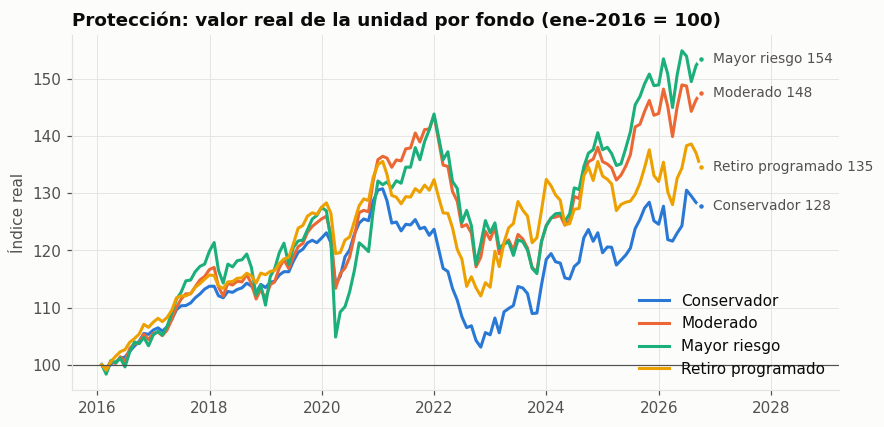

In [3]:
FONDOS = ["conservador", "moderado", "mayor_riesgo", "retiro_programado"]
NOMBRE = {"conservador": "Conservador", "moderado": "Moderado", "mayor_riesgo": "Mayor riesgo",
          "retiro_programado": "Retiro programado", "alternativo": "Alternativo"}

prot = mensual[mensual.afp == "Protección"].merge(ipc[["fecha", "ipc"]], on="fecha")
prot["real"] = prot.valor_unidad / prot.ipc

fig, ax = plt.subplots()
for i, f in enumerate(FONDOS):
    s = prot[prot.fondo == f].set_index("fecha")["real"]
    s = 100 * s / s.iloc[0]
    ax.plot(s.index, s.values, color=SERIES[i], label=NOMBRE[f])
    etiqueta_final(ax, s.index[-1], s.iloc[-1], f"{NOMBRE[f]} {s.iloc[-1]:.0f}", SERIES[i])
ax.axhline(100, color=INK2, lw=0.8)
ax.set_title("Protección: valor real de la unidad por fondo (ene-2016 = 100)")
ax.set_ylabel("Índice real")
ax.legend(loc="lower right")
ax.set_xlim(right=s.index[-1] + pd.Timedelta(days=900))
plt.show()

### 1.2 Rentabilidad real anualizada y volatilidad por AFP y fondo (feb-2016 a último mes completo)

In [4]:
r = mensual.dropna(subset=["r_real"])
g = r.groupby(["fondo", "afp"])["r_real"]
resumen = pd.DataFrame({
    "meses": g.size(),
    "r_real_anual": g.apply(lambda x: (1 + x).prod() ** (12 / len(x)) - 1),
    "volatilidad_anual": g.std() * np.sqrt(12),
    "peor_mes": g.min(),
    "max_caida": g.apply(lambda x: ((1 + x).cumprod() / (1 + x).cumprod().cummax() - 1).min()),
})
resumen["sharpe_real"] = resumen.r_real_anual / resumen.volatilidad_anual
resumen.style.format({"meses": "{:.0f}", "r_real_anual": "{:.2%}", "volatilidad_anual": "{:.2%}",
                      "peor_mes": "{:.2%}", "max_caida": "{:.2%}", "sharpe_real": "{:.2f}"})

### 1.3 Correlación de las rentabilidades reales mensuales entre fondos (Protección)

Para el bootstrap por bloques importa conservar esta estructura: los fondos se mueven juntos.

In [5]:
piv = r[r.afp == "Protección"].pivot(index="fecha", columns="fondo", values="r_real")[FONDOS]
piv.corr().rename(index=NOMBRE, columns=NOMBRE)

fondo,Conservador,Moderado,Mayor riesgo,Retiro programado
fondo,,,,
Conservador,1.0000,0.7992,0.7054,0.9159
Moderado,0.7992,1.0000,0.9536,0.7519
Mayor riesgo,0.7054,0.9536,1.0000,0.6426
Retiro programado,0.9159,0.7519,0.6426,1.0000


### 1.4 Autocorrelación de las rentabilidades mensuales

Si hay autocorrelación, el bootstrap debe remuestrear bloques y no meses sueltos.

In [6]:
from statsmodels.tsa.stattools import acf
pd.DataFrame({NOMBRE[f]: acf(piv[f], nlags=6)[1:] for f in FONDOS}, index=[f"rezago {k}" for k in range(1, 7)])

,Conservador,Moderado,Mayor riesgo,Retiro programado
rezago 1,0.1347,0.0776,0.0202,0.0912
rezago 2,0.0354,-0.0373,-0.0466,0.0503
rezago 3,-0.0025,0.0574,0.0049,0.0298
rezago 4,-0.1824,-0.0197,-0.0249,-0.2211
rezago 5,0.0822,0.0092,-0.0533,-0.0090
rezago 6,-0.0426,-0.1297,-0.1124,-0.1227


## 2. Inflación y salario mínimo

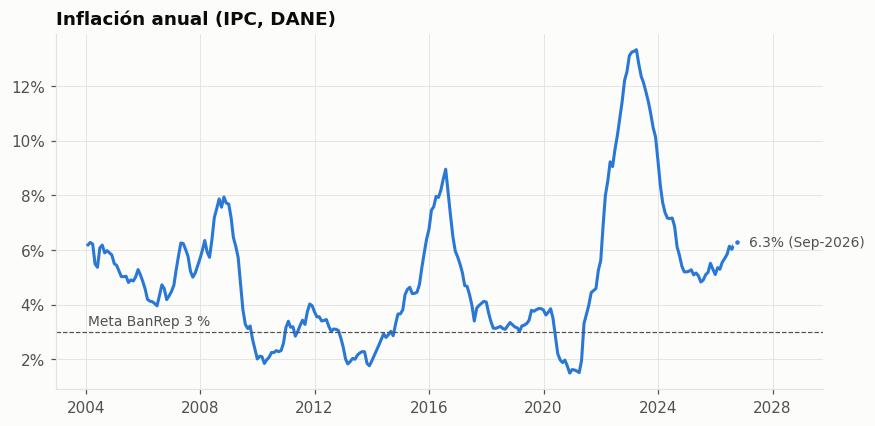

In [7]:
fig, ax = plt.subplots()
s = ipc.dropna(subset=["inflacion_anual"]).set_index("fecha")["inflacion_anual"]
ax.plot(s.index, s.values, color=SERIES[0])
ax.axhline(0.03, color=INK2, lw=0.8, ls="--")
ax.annotate("Meta BanRep 3 %", (s.index[0], 0.03), xytext=(0, 4), textcoords="offset points", color=INK2, fontsize=9)
etiqueta_final(ax, s.index[-1], s.iloc[-1], f"{s.iloc[-1]:.1%} ({s.index[-1]:%b-%Y})", SERIES[0])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title("Inflación anual (IPC, DANE)")
ax.set_xlim(right=s.index[-1] + pd.Timedelta(days=1100))
plt.show()

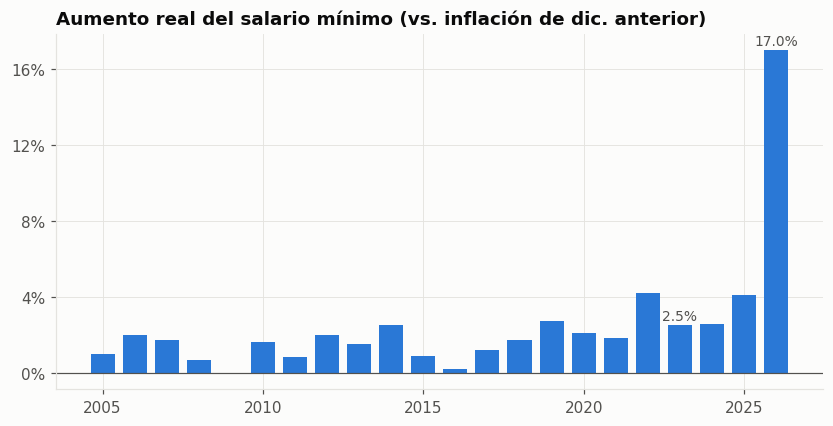

Crecimiento real promedio del SMMLV:
  2004–2026: 2.45% anual
  2004–2022: 1.60% anual
  2016–2026: 3.58% anual


In [8]:
smmlv = pd.read_parquet(P / "smmlv_anual.parquet")
sm = smmlv.dropna(subset=["var_real"])
fig, ax = plt.subplots()
ax.bar(sm.anio, sm.var_real, color=SERIES[0], width=0.75)
ax.axhline(0, color=INK2, lw=0.8)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.04))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
for a in (2023, 2026):
    v = sm.loc[sm.anio == a, "var_real"].iloc[0]
    ax.annotate(f"{v:.1%}", (a, v), xytext=(0, 3), textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.set_title("Aumento real del salario mínimo (vs. inflación de dic. anterior)")
plt.show()
print("Crecimiento real promedio del SMMLV:")
for a, b in [(2004, 2026), (2004, 2022), (2016, 2026)]:
    x = sm[sm.anio.between(a, b)].var_real
    print(f"  {a}–{b}: {(1 + x).prod() ** (1 / len(x)) - 1:.2%} anual")

## 3. Mortalidad de rentistas RV08

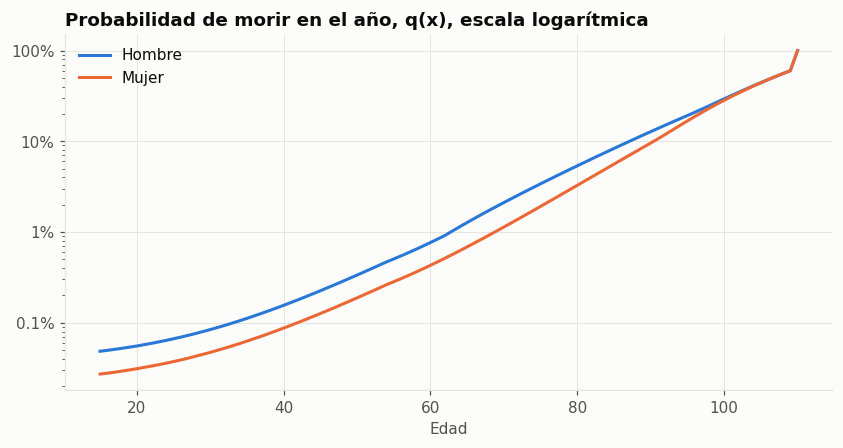

sexo,Hombre,Mujer
Esperanza de vida (años) a la edad,,
57,25.5000,29.7000
60,23.0000,27.0000
62,21.3000,25.3000
65,19.0000,22.7000
70,15.3000,18.6000


In [9]:
rv = pd.read_parquet(P / "mortalidad_rv08.parquet")
fig, ax = plt.subplots()
for i, sexo in enumerate(["Hombre", "Mujer"]):
    t = rv[rv.sexo == sexo]
    ax.plot(t.edad, t.qx, color=SERIES[i], label=sexo)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v * 100:g}%"))
ax.set_title("Probabilidad de morir en el año, q(x), escala logarítmica")
ax.set_xlabel("Edad")
ax.legend()
plt.show()
rv[rv.edad.isin([57, 60, 62, 65, 70])].pivot(index="edad", columns="sexo", values="ex").rename_axis(
    "Esperanza de vida (años) a la edad")

**Ojo con el riesgo de longevidad:** a la edad de pensión (57 mujeres, 62 hombres) la RV08 asigna más de 21 años de vida restante; las mujeres además se pensionan 5 años antes y viven más. Con el mismo saldo, su mesada es menor.

## 4. GEIH: cotización a pensión e ingresos

In [10]:
geih = pd.read_parquet(P / "geih_pensiones.parquet")
print(f"{len(geih):,} registros (personas-mes de 15 a 70 años), años {sorted(geih.anio.unique())}")
ocup = geih[geih.ocupado == 1]
tab = (ocup.groupby(["anio", "estado_pension"], observed=True).fex.sum()
       / ocup.groupby("anio").fex.sum()).unstack()
tab.style.format("{:.1%}").set_caption("Ocupados según P6920 (¿cotiza a pensión?)")

2,460,757 registros (personas-mes de 15 a 70 años), años [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


estado_pension,Cotiza,No cotiza,Pensionado
anio,,,
2022,41.8%,57.0%,1.2%
2023,43.3%,55.5%,1.3%
2024,43.9%,54.8%,1.4%
2025,44.2%,54.4%,1.4%


### 4.1 Tasa de cotización por edad y sexo (2025)

`cotiza` vale 1 si la persona está ocupada y cotiza, y 0 en cualquier otro caso (incluidos desocupados e inactivos). Es la probabilidad de que, en un mes cualquiera, una persona de esa edad esté aportando: el insumo directo de la densidad de cotización.

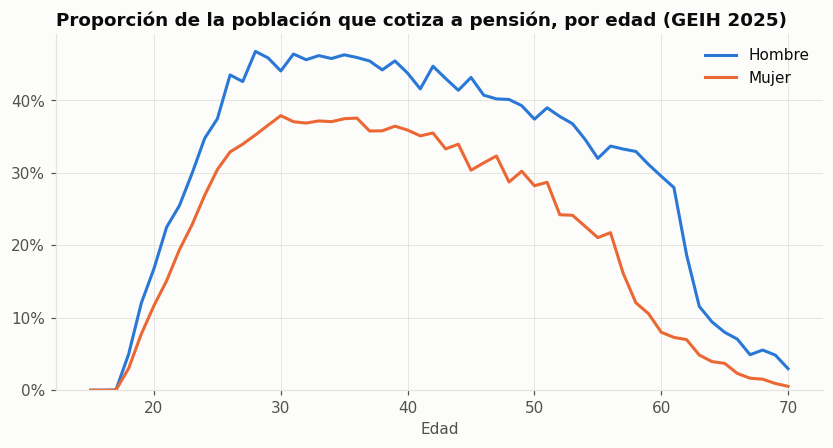

sexo,tasa_maxima,edad_maxima
Hombre,46.8%,28
Mujer,37.9%,30


In [11]:
g25 = geih[geih.anio == 2025]
fig, ax = plt.subplots()
maximos = []
for i, sexo in enumerate(["Hombre", "Mujer"]):
    t = g25[g25.sexo == sexo].groupby("edad").apply(media_ponderada, "cotiza", include_groups=False)
    ax.plot(t.index, t.values, color=SERIES[i], label=sexo)
    maximos.append({"sexo": sexo, "tasa_maxima": t.max(), "edad_maxima": int(t.idxmax())})
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0)
ax.set_title("Proporción de la población que cotiza a pensión, por edad (GEIH 2025)")
ax.set_xlabel("Edad")
ax.legend(loc="upper right")
plt.show()
pd.DataFrame(maximos).style.format({"tasa_maxima": "{:.1%}"}).hide(axis="index")

In [12]:
# Densidad de cotización "de corte transversal": promedio de la tasa entre los 20 y la edad de pensión.
# Multiplicada por los meses de esa ventana da las semanas esperadas de un afiliado típico (sin heterogeneidad).
SEM_MES = 30 / 7
filas = []
for sexo, edad_pen in [("Hombre", 62), ("Mujer", 57)]:
    t = g25[(g25.sexo == sexo) & g25.edad.between(20, edad_pen - 1)].groupby("edad").apply(
        media_ponderada, "cotiza", include_groups=False)
    filas.append({"sexo": sexo, "edad_pension": edad_pen, "densidad_promedio": t.mean(),
                  "semanas_esperadas": t.sum() * 12 * SEM_MES})
pd.DataFrame(filas).style.format({"densidad_promedio": "{:.1%}", "semanas_esperadas": "{:,.0f}"})

,sexo,edad_pension,densidad_promedio,semanas_esperadas
0,Hombre,62,38.7%,836
1,Mujer,57,30.6%,582


### 4.2 Tasa de cotización por nivel educativo (2025)

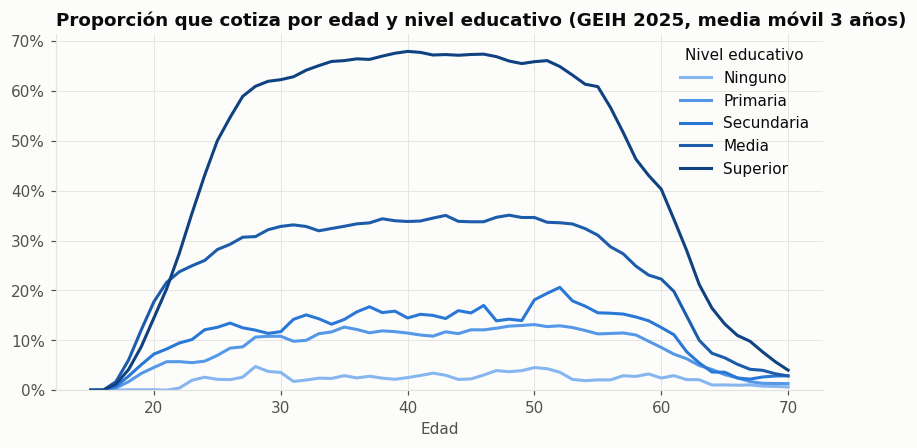

In [13]:
NIV = ["Ninguno", "Primaria", "Secundaria", "Media", "Superior"]
fig, ax = plt.subplots()
for i, n in enumerate(NIV):
    t = g25[g25.nivel_educativo == n].groupby("edad").apply(media_ponderada, "cotiza", include_groups=False)
    t = t.rolling(3, center=True, min_periods=1).mean()
    ax.plot(t.index, t.values, color=ORDINAL_AZUL[i], label=n)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0)
ax.set_title("Proporción que cotiza por edad y nivel educativo (GEIH 2025, media móvil 3 años)")
ax.set_xlabel("Edad")
ax.legend(title="Nivel educativo", loc="upper right")
plt.show()

### 4.3 Ingreso laboral de los cotizantes por edad (en salarios mínimos, 2025)

Perfil edad-ingreso que alimentará la ecuación de Mincer del paso 4. Se usa la mediana ponderada para que los ingresos extremos no la distorsionen.

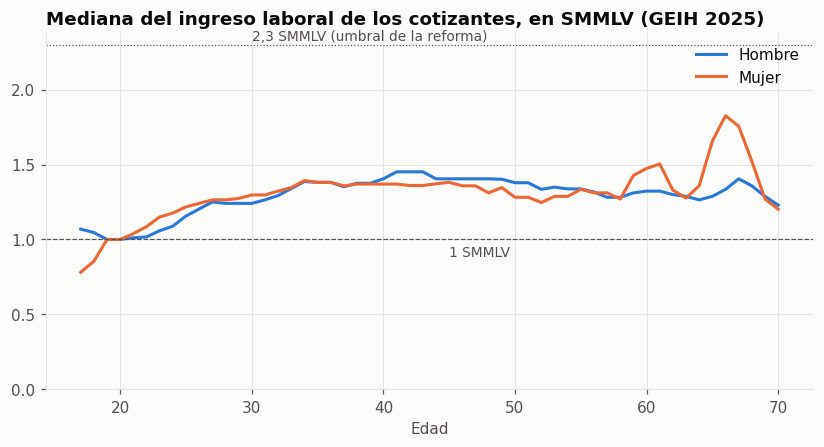

Cotizantes con ingreso <= 2,3 SMMLV: 78.1%


In [14]:
cot = g25[(g25.cotiza == 1) & (g25.ingreso_laboral > 0)]
fig, ax = plt.subplots()
for i, sexo in enumerate(["Hombre", "Mujer"]):
    t = cot[cot.sexo == sexo].groupby("edad").apply(lambda d: mediana_ponderada(d.ratio_smlv, d.fex),
                                                     include_groups=False)
    t = t.rolling(3, center=True, min_periods=1).mean()
    ax.plot(t.index, t.values, color=SERIES[i], label=sexo)
ax.axhline(1, color=INK2, lw=0.8, ls="--")
ax.axhline(2.3, color=INK2, lw=0.8, ls=":")
ax.annotate("1 SMMLV", (45, 1), xytext=(0, -4), textcoords="offset points", va="top", color=INK2, fontsize=9)
ax.annotate("2,3 SMMLV (umbral de la reforma)", (30, 2.3), xytext=(0, 3), textcoords="offset points", color=INK2, fontsize=9)
ax.set_title("Mediana del ingreso laboral de los cotizantes, en SMMLV (GEIH 2025)")
ax.set_xlabel("Edad")
ax.set_ylim(0)
ax.legend(loc="upper right")
plt.show()
share = np.average(cot.ratio_smlv <= 2.3, weights=cot.fex)
print(f"Cotizantes con ingreso <= 2,3 SMMLV: {share:.1%}")

### 4.4 Cotización por posición ocupacional (ocupados, 2025)

In [15]:
o25 = g25[g25.ocupado == 1]
(o25.groupby("posicion_ocupacional").apply(lambda d: pd.Series({
    "participacion_ocupados": d.fex.sum() / o25.fex.sum(),
    "tasa_cotizacion": media_ponderada(d, "cotiza")}), include_groups=False)
   .sort_values("participacion_ocupados", ascending=False)
   .style.format("{:.1%}"))

,participacion_ocupados,tasa_cotizacion
posicion_ocupacional,,
Empleado particular,45.2%,72.0%
Cuenta propia,40.5%,14.9%
Empleado del gobierno,3.7%,94.9%
Jornalero o peón,3.4%,18.4%
Empleado doméstico,3.0%,20.0%
Patrón o empleador,2.4%,34.0%
Familiar sin remuneración,1.8%,2.7%
Otro,0.0%,7.6%


## Hallazgos para el diseño del simulador

**Rentabilidades (paso 3)**
- Rentabilidad real anualizada en Protección (feb-2016 a sep-2026): conservador 2,3 %, moderado 3,7 %, mayor riesgo 4,1 %, retiro programado 2,8 %. Volatilidad anual de 5,9 % a 8,7 %.
- **El conservador no fue "seguro" en términos reales:** su máxima caída real (−21 %, durante el choque de inflación y tasas de 2021–2022) fue *mayor* que la del fondo de mayor riesgo (−19 %). Es un insumo interesante para el análisis de multifondos y una historia para el README.
- Los fondos están muy correlacionados (moderado vs. mayor riesgo: 0,95). Hay que remuestrear **los cuatro fondos en el mismo mes** para conservar esa estructura.
- La autocorrelación mensual es baja en el primer rezago (0,02–0,13), con algo de estructura en los rezagos 4 y 6. Un bootstrap por **bloques de 3–6 meses** es razonable; se calibrará en el paso 3.
- Solo hay 10,7 años de historia (desde 2016) y en ellos ocurrieron el COVID y la inflación de 2022. Esto refuerza la idea de comparar el bootstrap con un modelo paramétrico.

**Supuestos macro**
- El salario mínimo creció 1,6 % real anual entre 2004 y 2022, pero 3,6 % entre 2016 y 2026 por los aumentos de 2023 y 2026 (17 % real). El supuesto de `config/parametros.yaml` (1 %) es conservador y debe ir al análisis de sensibilidad.
- La inflación está en 6,3 % (sep-2026), lejos de la meta del 3 % que se usa como supuesto de largo plazo.

**Mortalidad (paso 6)**
- RV08: una mujer de 57 años tiene 29,7 años de vida esperada y un hombre de 62, 21,3. Con el mismo saldo, la mesada de la mujer será sensiblemente menor. La brecha de género sale del modelo sin forzarla.

**Densidad de cotización (paso 5), el hallazgo central**
- En 2025 cotiza el 44 % de los ocupados. Sobre toda la población, el máximo es 47 % (hombres, ~28 años) y 38 % (mujeres, ~30 años).
- Si una persona cotizara con la tasa *promedio* de su edad entre los 20 años y la edad de pensión, acumularía unas **836 semanas (hombres) y 582 (mujeres)**, lejos de las 1.150–1.300 exigidas.
- Ese promedio mezcla a quienes cotizan casi siempre con quienes nunca lo hacen: la cotización depende fuertemente de la educación (máximo ~67 % con educación superior vs. ~15 % con secundaria) y de la posición ocupacional (72 % de los empleados particulares vs. 15 % de los cuentapropistas, que son el 40 % de los ocupados). El paso 5 debe modelar esa **heterogeneidad y persistencia** (cadena de Markov por tipo de trabajador), no aplicar una tasa promedio.

**Salarios y reforma (pasos 4 y 6)**
- La mediana del ingreso de los cotizantes se mueve entre 1 y 1,5 SMMLV durante toda la vida laboral, y el 78 % de los cotizantes gana hasta 2,3 SMMLV. Bajo la reforma, la mayoría cotizaría solo a Colpensiones: el componente de ahorro individual sería relevante para una minoría de ingresos altos.